# LusoEnergia — Parte IV: Monitorizar

Nesta parte, as leituras são tratadas como se chegassem uma a uma, em tempo real. Cada estatística é atualizada com a leitura nova, sem nunca olhar para a série completa (exceto para verificar os resultados). \
Os minutos sem leitura (as 4 lacunas longas) são simplesmente saltados, como se o sensor não tivesse enviado nada.

As funções do fluxo estão em `src/fluxo.py`, para serem depois usadas no dashboard.

In [32]:
# Parte IV - configuração e dados tratados (gerados no notebook das Partes I e II)
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from src.fluxo import Welford, JanelaDeslizante, EWMA
from src.utils import guardar_figura

AZUL, LARANJA, TINTA, TINTA_2, GRELHA = "#3a8fd6", "#7b1e3a", "#2b2b28", "#6b6a64", "#e4e3de"
DIAS = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
MESES_PT = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]


def estilo(ax):
    """Eixos discretos: sem moldura, grelha leve (o mesmo estilo das Partes I e II)."""
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
    for sp in ("left", "bottom"):
        ax.spines[sp].set_color(GRELHA)
    ax.tick_params(colors=TINTA_2, labelsize=9, length=0)
    ax.grid(axis="y", color=GRELHA, lw=0.8)
    ax.set_axisbelow(True)


tratado = pd.read_csv("data/processed/consumo_tratado.csv", index_col=0, parse_dates=True)
serie = tratado["Global_active_power"]             # kW, uma leitura por minuto
print(f"{len(serie)} minutos | {serie.isna().sum()} sem leitura (lacunas > 3 h) | "
      f"{serie.index.min():%Y-%m-%d} a {serie.index.max():%Y-%m-%d}")


790560 minutos | 4196 sem leitura (lacunas > 3 h) | 2008-05-01 a 2009-10-31


Comprova-se que o fluxo tem **790560 minutos** de **1 de maio de 2008 a 31 de outubro de 2009**. \
Destes, **4196 não têm leitura**, pois tratam-se das **lacunas de mais de 3 horas** que se decidiu não preencher na parte da Fundação (datas de 13 a 15 de junho e 13 de agosto de 2009). \
No replay, esses minutos são saltados, como se o sensor não tivesse enviado nada.

### 4.1 Replay do fluxo

Cada leitura atualiza três estatísticas:
- **Média e variância globais (Welford):** são atualizadas a cada leitura, sem guardar as leituras anteriores (ex: esta casa gasta em média 1 kW).
- **Janela deslizante de 60 minutos:** representa a média da última hora, esquecendo de repente o que tem mais de 60 minutos. Se faltarem minutos, nunca abrange mais de uma hora (ex: na última hora gastou-se 1,4 kW).
- **EWMA (média móvel exponencial):** cada leitura nova pesa `alpha` e o passado vai perdendo peso aos poucos. Usa-se `alpha = 2/(60+1)`, para ter uma memória comparável à janela de 60 minutos.

In [33]:
# 4.1 - Replay do fluxo: cada leitura é processada uma a uma, pela ordem em que chega
ALPHA = 2 / (60 + 1)                                # EWMA com "memória" comparável a 60 min

welford = Welford()
janela = JanelaDeslizante(minutos=60)
ewma = EWMA(alpha=ALPHA)
tempos, med_global, med_janela, med_ewma = [], [], [], []

inicio = time.perf_counter()
for t, x in serie.items():                          # elemento a elemento
    if np.isnan(x):                                 # minuto sem leitura: o sensor não enviou nada
        continue
    welford.atualizar(x)
    janela.atualizar(t, x)
    ewma.atualizar(x)
    tempos.append(t)                                # guardado só para os gráficos
    med_global.append(welford.media)                # média global ATÉ este minuto
    med_janela.append(janela.media)
    med_ewma.append(ewma.media)
duracao = time.perf_counter() - inicio

online = pd.DataFrame({"welford": med_global, "janela_60min": med_janela, "ewma": med_ewma}, index=pd.DatetimeIndex(tempos))
print(f"{welford.n} leituras processadas em {duracao:.1f} s ({1e6 * duracao / welford.n:.1f} µs por leitura)")


786364 leituras processadas em 6.9 s (8.8 µs por leitura)


Devido ao facto de as lacunas sem leitura terem sido ignoradas, foram processadas **786364 leituras** ao invés de 790560, uma a uma, em **6.8 segundos**.

In [34]:
# Verificação contra o cálculo em batch (o ÚNICO sítio onde se usa a série completa)
ok = serie.dropna()
verif = pd.DataFrame({
    "Welford (online)": [welford.n, welford.media, welford.variancia],
    "pandas (batch)": [len(ok), ok.mean(), ok.var()],
}, index=["n", "média (kW)", "variância (kW²)"])
verif["diferença absoluta"] = (verif["Welford (online)"] - verif["pandas (batch)"]).abs()
assert np.isclose(welford.media, ok.mean()) and np.isclose(welford.variancia, ok.var())

# A janela de 60 min também se verifica contra o rolling do pandas
rolling = ok.rolling("60min").mean()
dif_janela = (online["janela_60min"] - rolling).abs().max()
assert dif_janela < 1e-9, dif_janela
print(f"Janela de 60 min: diferença máxima face ao rolling do pandas = {dif_janela:.1e} kW")
verif


Janela de 60 min: diferença máxima face ao rolling do pandas = 6.7e-12 kW


,Welford (online),pandas (batch),diferença absoluta
n,786364.000000,786364.000000,0.000000e+00
média (kW),1.008775,1.008775,3.219647e-14
variância (kW²),0.984745,0.984745,8.326673e-15


Com base na tabela, podemos verificar que:
- Com **Welford**, foram processados o mesmo número de leituras, e a média e a variância são iguais às do pandas, com diferenças da ordem de 10⁻¹⁴, ou seja, apenas erros de arredondamento do computador.
- Com a **janela de 60 min**, a média coincide, minuto a minuto, com o `rolling` do pandas, com uma diferença máxima de cerca de 7 × 10⁻¹² kW.

Assim, **as estatísticas calculadas em fluxo dão o mesmo resultado que o cálculo em batch**, a menos de erros de arredondamento, sem nunca precisar da série completa, onde o Welford guarda apenas três números (n, média e soma dos desvios ao quadrado) e a janela guarda só as leituras da última hora.

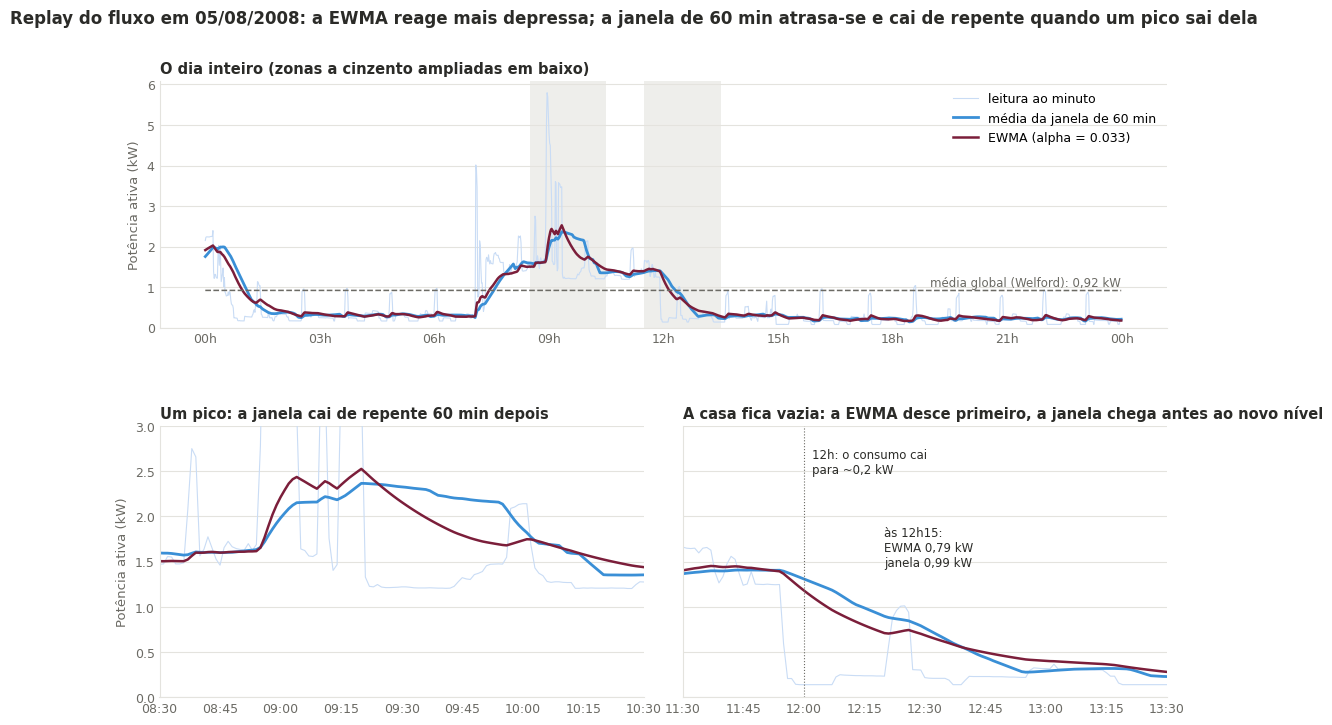

In [35]:
def plot_dia_fluxo(dia, caminho_png=None):
    """Um dia do fluxo: visão geral (em cima) e dois zooms (em baixo) onde a janela e a EWMA se distinguem."""
    d = pd.Timestamp(dia)
    h = lambda hhmm: d + pd.Timedelta(f"{hhmm}:00")                  # "08:30" -> instante desse dia
    x, o = serie.loc[h("00:00"):h("23:59")], online.loc[h("00:00"):h("23:59")]
    zooms = [("08:30", "10:30", "Um pico: a janela cai de repente 60 min depois"),
             ("11:30", "13:30", "A casa fica vazia: a EWMA desce primeiro, a janela chega antes ao novo nível")]

    fig = plt.figure(figsize=(13, 8))
    grelha = fig.add_gridspec(2, 2, height_ratios=[1, 1.1], hspace=0.38, wspace=0.08)
    ax = fig.add_subplot(grelha[0, :])
    zs = [fig.add_subplot(grelha[1, 0]), fig.add_subplot(grelha[1, 1])]

    for a in [ax] + zs:
        a.plot(x.index, x.values, color="#c9dcf5", lw=0.8, label="leitura ao minuto")
        a.plot(o.index, o["janela_60min"], color=AZUL, lw=2, label="média da janela de 60 min")
        a.plot(o.index, o["ewma"], color=LARANJA, lw=1.8, label=f"EWMA (alpha = {ALPHA:.3f})")
        a.set_ylim(0, None)
        estilo(a)
    ax.plot(o.index, o["welford"], color=TINTA_2, ls="--", lw=1.1)
    ax.text(h("23:59"), o["welford"].iloc[-1] + 0.12, f"média global (Welford): {o['welford'].iloc[-1]:.2f} kW".replace(".", ","),
            ha="right", fontsize=8.5, color=TINTA_2)
    for z0, z1, _ in zooms:                                           # zonas ampliadas em baixo
        ax.axvspan(h(z0), h(z1), color=GRELHA, alpha=0.6, lw=0)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Hh"))
    ax.set_ylabel("Potência ativa (kW)", fontsize=9.5, color=TINTA_2)
    ax.legend(frameon=False, fontsize=9, loc="upper right")
    ax.set_title("O dia inteiro (zonas a cinzento ampliadas em baixo)", loc="left", fontsize=10.5,
                 color=TINTA, fontweight="bold")

    for a, (z0, z1, titulo) in zip(zs, zooms):
        a.set_xlim(h(z0), h(z1))
        a.set_ylim(0, 3)
        a.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
        a.set_title(titulo, loc="left", fontsize=10.5, color=TINTA, fontweight="bold")
    zs[0].set_ylabel("Potência ativa (kW)", fontsize=9.5, color=TINTA_2)
    zs[1].set_yticklabels([])

    # Zoom 1: o pico das 8h57 sai da janela uma hora depois
    pico = x.loc[h("08:30"):h("10:30")].idxmax()
    queda = o["janela_60min"].loc[h("09:30"):h("10:30")].diff().idxmin()

    # Zoom 2: às 12h o consumo cai para ~0,2 kW; valores 15 min depois
    t15 = h("12:15")
    zs[1].axvline(h("12:00"), color=TINTA_2, lw=0.8, ls=":")
    zs[1].text(h("12:02"), 2.75, "12h: o consumo cai\npara ~0,2 kW", fontsize=8.5, color=TINTA, va="top")
    zs[1].text(h("12:20"), 1.45, f"às 12h15:\nEWMA {o.loc[t15, 'ewma']:.2f} kW\njanela {o.loc[t15, 'janela_60min']:.2f} kW".replace(".", ","),
               fontsize=8.5, color=TINTA)

    fig.suptitle(f"Replay do fluxo em {d:%d/%m/%Y}: a EWMA reage mais depressa; a janela de 60 min atrasa-se "
                 "e cai de repente quando um pico sai dela", x=0.01, ha="left", y=0.97, fontsize=12,
                 fontweight="bold", color=TINTA)
    if caminho_png:
        fig.savefig(caminho_png, dpi=150, bbox_inches="tight", facecolor="white")
    return fig


fig = plot_dia_fluxo("2008-08-05")
guardar_figura(fig, "parte_IV", "fluxo_dia")
plt.show()

Com base neste gráfico, podemos analisar que:
- **A EWMA reage mais depressa às mudanças** pois, quando a casa fica vazia, às 12h, desce logo (às 12h15 está em 0,79 kW, contra 0,99 kW da janela), mas fica com uma "cauda" lenta, porque nunca esquece por completo o passado;
- **A janela de 60 min reage com atraso e tem "degraus"**, pois o pico das 8h57 mantém a média alta durante uma hora e, quando sai da janela, às 9h57, a média cai de repente. Em contrapartida, ao fim de 60 minutos esquece tudo, por isso chega ao novo nível da casa vazia antes da EWMA;
- **A média global (Welford) quase não se mexe** (cerca de 0,92 kW durante todo o dia), porque um único dia pesa pouco face a centenas de milhares de leituras. Serve para conhecer a casa a longo prazo e não para acompanhar o que está a acontecer no momento.

### 4.2 Drift e anomalias

Guarda uma janela de valores recentes (**ADWIN (Adaptive Windowing)** e, a cada valor novo, verifica se a média da parte mais antiga da janela é estatisticamente diferente da média da parte mais recente. Se for, assinala uma mudança (*drift*) e esquece a parte antiga. \
O parâmetro `delta` é o que controla a exigência - quanto menor for, mais provas são precisas para assinalar uma mudança. 
Aplica-se a dois agregados, ambos calculados no próprio fluxo (com a classe `Agregador`), sendo eles as médias de 15 minutos e a energia de cada dia (kWh).

In [36]:
# 4.2 - Agregados de 15 min e diários, calculados no próprio fluxo, e ADWIN sobre cada um
from river.drift import ADWIN
from src.fluxo import Agregador, AlarmeZ

DELTA = 0.002                                      # confiança do ADWIN (valor por omissão do river)
ag15, agdia = Agregador("15min"), Agregador("1D")
adwin15, adwin_dia = ADWIN(delta=DELTA), ADWIN(delta=DELTA)
q15, dia_kwh, det15, det_dia = [], [], [], []


def novo_15min(fechado):
    """Recebe um período de 15 min acabado de fechar: guarda-o e passa-o ao ADWIN."""
    inicio_p, media, _ = fechado
    q15.append((inicio_p, media))
    adwin15.update(media)
    if adwin15.drift_detected:
        det15.append(inicio_p)


def novo_dia(fechado):
    """Recebe um dia acabado de fechar: energia do dia (kWh) para o ADWIN."""
    inicio_p, media, _ = fechado
    kwh = media * 24                               # potência média (kW) x 24 h = energia do dia (kWh)
    dia_kwh.append((inicio_p, kwh))
    adwin_dia.update(kwh)
    if adwin_dia.drift_detected:
        det_dia.append(inicio_p)


for t, x in serie.items():                         # o mesmo fluxo, leitura a leitura
    if np.isnan(x):
        continue
    f = ag15.atualizar(t, x)
    if f:
        novo_15min(f)
    f = agdia.atualizar(t, x)
    if f:
        novo_dia(f)
novo_15min(ag15.fechar())                          # últimos períodos, ainda abertos no fim do fluxo
novo_dia(agdia.fechar())

q15 = pd.Series(dict(q15), name="kW")
dia = pd.Series(dict(dia_kwh), name="kWh")
det15, det_dia = pd.DatetimeIndex(det15), pd.DatetimeIndex(det_dia)
print(f"{len(q15)} períodos de 15 min | {len(dia)} dias")
print(f"ADWIN sobre os agregados de 15 min: {len(det15)} deteções")
print(f"ADWIN sobre a energia diária: {len(det_dia)} deteções -> {[f'{d:%d/%m/%Y}' for d in det_dia]}")


52425 períodos de 15 min | 548 dias
ADWIN sobre os agregados de 15 min: 156 deteções
ADWIN sobre a energia diária: 4 deteções -> ['04/08/2008', '07/10/2008', '21/06/2009', '25/09/2009']


Com base no output, podemos ver que:
- O fluxo deu origem a **52425 períodos de 15 minutos** e **548 dias**;
- Sobre os mesmos dados, o **ADWIN assinala 156 mudanças** quando olha para as médias de 15 minutos, mas apenas 4 quando olha para a energia de cada dia;
- A diferença mostra que **a escolha do agregado muda completamente o que o ADWIN encontra**. A seguir vê-se em que horas e meses caem as 156 deteções e o que significam as 4 deteções diárias.

In [37]:
# Em que horas do dia e em que meses acontecem as deteções sobre os agregados de 15 min?
por_hora = pd.Series(det15.hour).value_counts().reindex(range(24), fill_value=0)
print("Deteções por hora do dia:", por_hora[por_hora > 0].to_dict())
print(f"Às 7h, 15h e 23h: {por_hora[[7, 15, 23]].sum()} de {len(det15)} "
      f"({por_hora[[7, 15, 23]].sum() / len(det15):.0%})")
pd.DataFrame({"deteções": pd.Series(1, index=det15).resample("MS").sum()}).T.rename(
    columns=lambda m: f"{MESES_PT[m.month - 1]}/{m:%y}")


Deteções por hora do dia: {5: 2, 6: 3, 7: 33, 13: 3, 14: 6, 15: 37, 21: 14, 22: 2, 23: 56}
Às 7h, 15h e 23h: 126 de 156 (81%)


,mai/08,jun/08,jul/08,ago/08,set/08,out/08,nov/08,dez/08,jan/09,fev/09,mar/09,abr/09,mai/09,jun/09,jul/09,ago/09,set/09,out/09
deteções,12,9,6,5,3,13,15,11,16,14,7,6,7,6,5,6,4,11


texto aqui

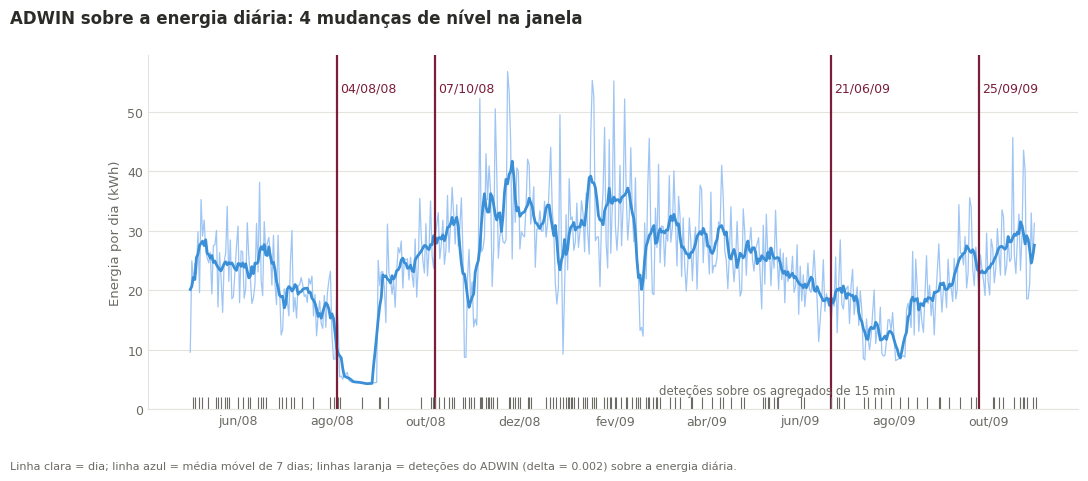

In [38]:
def plot_adwin(caminho_png=None):
    """Energia diária com as deteções do ADWIN (diário: linhas; 15 min: traços em baixo)."""
    fig, ax = plt.subplots(figsize=(12, 4.6))
    ax.plot(dia.index, dia.values, color="#9ec5f4", lw=0.9)
    ax.plot(dia.index, dia.rolling(7, center=True, min_periods=4).mean(), color=AZUL, lw=2)
    for d in det_dia:
        ax.axvline(d, color=LARANJA, lw=1.6)
        ax.text(d + pd.Timedelta(days=2), dia.max() * 0.97, f"{d:%d/%m/%y}", color=LARANJA, fontsize=9, va="top")
    ax.plot(det15, np.full(len(det15), 1.0), "|", color=TINTA_2, ms=9, mew=0.8)
    ax.text(pd.Timestamp("2009-03-01"), 2.6, "deteções sobre os agregados de 15 min", fontsize=8.5, color=TINTA_2)
    ax.set_ylim(0, None)
    ax.set_ylabel("Energia por dia (kWh)", fontsize=9.5, color=TINTA_2)
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: (lambda d: f"{MESES_PT[d.month - 1]}/{d:%y}")(mdates.num2date(x))))
    estilo(ax)
    fig.suptitle("ADWIN sobre a energia diária: 4 mudanças de nível na janela", x=0.01, ha="left",
                 fontsize=12, fontweight="bold", color=TINTA)
    fig.text(0.01, -0.02, f"Linha clara = dia; linha azul = média móvel de 7 dias; linhas laranja = deteções do ADWIN "
             f"(delta = {DELTA}) sobre a energia diária.", fontsize=8, color=TINTA_2)
    if caminho_png:
        fig.savefig(caminho_png, dpi=150, bbox_inches="tight", facecolor="white")
    return fig


fig = plot_adwin()
guardar_figura(fig, "parte_IV", "adwin")
plt.show()


texto aqui

**Leitura.**
- **Sobre os agregados de 15 min, o ADWIN assinala 156 mudanças, 81 % delas às 7h, 15h e 23h.** Ou seja, reage sobretudo ao ciclo do próprio dia (acordar, tarde, deitar), que não é uma mudança de comportamento. Há mais deteções de outubro a fevereiro, quando o consumo varia mais. Para encontrar mudanças de comportamento, esta granularidade não serve.
- **Sobre a energia diária, assinala só 4 mudanças, todas com explicação:**
  - **04/08/2008:** início da ausência de agosto (a casa vazia da 2.1). Mudança temporária.
  - **07/10/2008:** subida de outono. Sazonal.
  - **21/06/2009:** descida de verão. Sazonal.
  - **25/09/2009:** nova subida de outono. Sazonal, e repete a de 2008.
- A subida de outono aparece nos dois anos: é **drift recorrente**. A descida de verão de 2008 não aparece porque a janela só começa em maio.
- **Limitação:** o regresso das férias (31/08/2008) não é assinalado à parte. Depois da deteção de 04/08, o ADWIN só volta a assinalar a 07/10, já com o consumo de outono.

**Sazonal ou estrutural?** Para distinguir, compara-se cada dia com a mesma semana do ano anterior, que já passou no fluxo (por isso não há batota). Uma mudança sazonal acontece nos dois anos e anula-se nesta diferença; uma mudança estrutural (uma forma de consumir nova, que não existia no ano anterior) não se anula. Com uma janela de 18 meses, só é possível a partir de maio de 2009.

In [39]:
# Sazonal ou estrutural? Comparar cada dia com o MESMO período do ano anterior (que já passou no fluxo)
# Uma mudança sazonal repete-se todos os anos e desaparece nesta diferença; uma estrutural não.
adwin_aa = ADWIN(delta=DELTA)
passado = {}                                       # energia dos dias que já chegaram
residuo, det_aa = [], []
for d, kwh in dia.items():                         # dias pela ordem em que chegam
    ref = [passado[r] for r in pd.date_range(d - pd.DateOffset(years=1) - pd.Timedelta(days=3), periods=7)
           if r in passado]                        # semana à volta do mesmo dia, um ano antes
    if len(ref) >= 4:
        r = kwh - np.mean(ref)
        residuo.append((d, r))
        adwin_aa.update(r)
        if adwin_aa.drift_detected:
            det_aa.append(d)
    passado[d] = kwh

residuo = pd.Series(dict(residuo), name="kWh face ao ano anterior")
print(f"Dias com ano anterior disponível: {len(residuo)} ({residuo.index.min():%d/%m/%Y} a {residuo.index.max():%d/%m/%Y})")
print(f"ADWIN sobre a diferença face ao ano anterior: {[f'{d:%d/%m/%Y}' for d in det_aa]}")
residuo.resample("MS").mean().round(1).rename(lambda m: f"{MESES_PT[m.month - 1]}/{m:%y}").to_frame("diferença média (kWh/dia)").T


Dias com ano anterior disponível: 183 (01/05/2009 a 31/10/2009)
ADWIN sobre a diferença face ao ano anterior: ['06/09/2009']


,mai/09,jun/09,jul/09,ago/09,set/09,out/09
diferença média (kWh/dia),-0.4,-4.1,-3.8,9.0,0.1,0.4


texto aqui

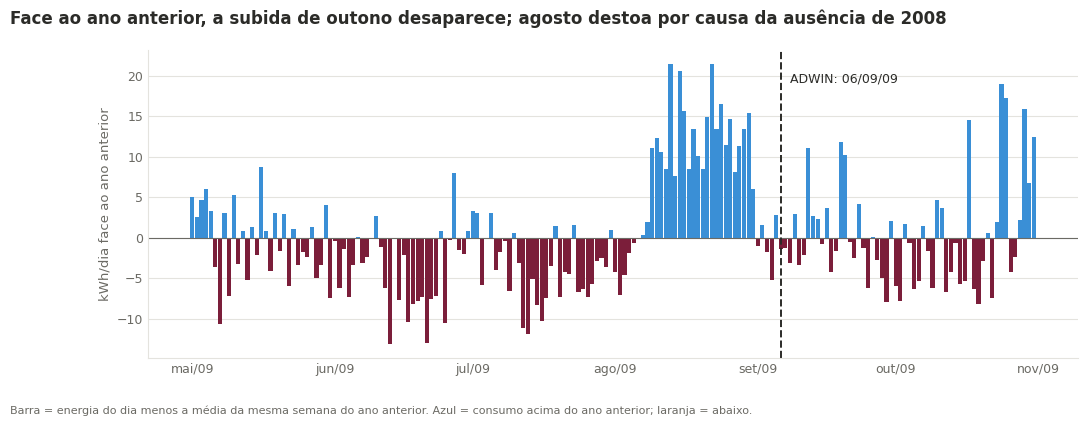

In [40]:
def plot_ano_contra_ano(caminho_png=None):
    """Diferença diária face ao mesmo período do ano anterior, com as deteções do ADWIN."""
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.bar(residuo.index, residuo.values, width=0.9, color=np.where(residuo.values >= 0, AZUL, LARANJA))
    ax.axhline(0, color=TINTA_2, lw=0.8)
    for d in det_aa:
        ax.axvline(d, color=TINTA, lw=1.4, ls="--")
        ax.text(d + pd.Timedelta(days=2), residuo.max() * 0.95, f"ADWIN: {d:%d/%m/%y}", fontsize=9, color=TINTA, va="top")
    ax.set_ylabel("kWh/dia face ao ano anterior", fontsize=9.5, color=TINTA_2)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: (lambda d: f"{MESES_PT[d.month - 1]}/{d:%y}")(mdates.num2date(x))))
    estilo(ax)
    fig.suptitle("Face ao ano anterior, a subida de outono desaparece; agosto destoa por causa da ausência de 2008",
                 x=0.01, ha="left", fontsize=12, fontweight="bold", color=TINTA)
    fig.text(0.01, -0.03, "Barra = energia do dia menos a média da mesma semana do ano anterior. "
             "Azul = consumo acima do ano anterior; laranja = abaixo.", fontsize=8, color=TINTA_2)
    if caminho_png:
        fig.savefig(caminho_png, dpi=150, bbox_inches="tight", facecolor="white")
    return fig


fig = plot_ano_contra_ano()
guardar_figura(fig, "parte_IV", "adwin_ano_contra_ano")
plt.show()


texto aqui

**Leitura.**
- A subida de outono de 2009 (25/09), que o ADWIN tinha assinalado na energia diária, **desaparece** quando se compara com o ano anterior: setembro e outubro de 2009 consomem o mesmo que em 2008 (+0,1 e +0,4 kWh/dia). Confirma que é drift recorrente, ou seja, sazonal.
- A única deteção é a 06/09/2009, no fim do bloco de agosto, que fica muito acima do ano anterior (+9 kWh/dia). Não é uma mudança de 2009: é o reflexo da ausência de agosto de 2008, que tornou a referência anormalmente baixa.
- Junho e julho de 2009 consomem cerca de 4 kWh/dia menos do que em 2008, mas de forma irregular, e o ADWIN não o assinala. Com um só ano de comparação, não se pode dizer se é uma mudança permanente.
- **Regra prática:** uma deteção que se repete na mesma altura do ano e desaparece na comparação com o ano anterior é sazonal. Uma que persiste nessa comparação, e que não se explica por um acontecimento pontual no ano de referência, é candidata a mudança estrutural.

### Alarme de anomalias com z-score em janela

Para cada leitura calcula-se `z = (leitura − média da janela) / desvio-padrão da janela`, usando a janela **anterior**, sem a própria leitura. Há alarme quando |z| ultrapassa o limiar. Começa-se ao minuto, com janelas de 30 a 120 min e limiares de 3 a 5.

In [41]:
# Alarme de anomalias com z-score em janela, ao MINUTO: quantos alarmes para cada janela e limiar?
N_DIAS = serie.dropna().index.normalize().nunique()
em_ausencia = lambda idx: (idx >= "2008-08-06") & (idx < "2008-08-31")   # casa vazia (2.1)


def contar_alarmes(fluxo, **config):
    """Passa o fluxo pelo AlarmeZ e devolve os alarmes (instante -> z)."""
    alarme = AlarmeZ(**config)
    out = {}
    for t, x in fluxo.items():
        if np.isnan(x):
            continue
        z, a = alarme.atualizar(t, x)
        if a:
            out[t] = z
    return pd.Series(out, dtype=float)


linhas = []
for minutos in (30, 60, 120):
    for limiar in (3, 4, 5):
        a = contar_alarmes(serie, minutos=minutos, limiar=limiar, min_leituras=minutos // 2)
        linhas.append({"janela (min)": minutos, "limiar |z|": limiar, "alarmes": len(a),
                       "alarmes por dia": len(a) / N_DIAS,
                       "por dia, na casa vazia": em_ausencia(a.index).sum() / 25})
tab_minuto = pd.DataFrame(linhas).set_index(["janela (min)", "limiar |z|"])
tab_minuto.round(1)


alarmes  alarmes por dia  por dia, na casa vazia
janela (min) limiar |z|                                                  
30           3             46756             85.3                    85.9
             4             25301             46.2                    45.1
             5             15761             28.8                    27.4
60           3             37520             68.5                    70.8
             4             22597             41.2                    58.5
             5             13536             24.7                    37.8
120          3             34278             62.6                    62.4
             4             16305             29.8                    31.8
             5              8134             14.8                     7.2

**Ao minuto, o alarme é inutilizável.** Mesmo na configuração mais exigente (120 min, limiar 5) há cerca de 15 alarmes por dia, e nas outras chega a 85. Cada aparelho que liga (forno, chaleira, máquina) é uma subida brusca face à última hora. Na casa vazia, as janelas curtas dão tantos ou mais alarmes do que nos dias normais: a janela é quase constante, o desvio-padrão fica minúsculo e o simples ciclo do frigorífico dá valores de z enormes.

Por isso, testa-se o mesmo alarme sobre as médias de 15 min, com janelas mais longas e um desvio mínimo de 0,1 kW (abaixo disto, a janela é tratada como quase constante).

In [42]:
# Alternativa: o mesmo alarme sobre as médias de 15 min, com janelas mais longas e um desvio mínimo
DESVIO_MIN = 0.1                                   # kW: abaixo disto, a janela é tratada como "quase constante"
linhas = []
for horas in (6, 24, 24 * 7):
    for limiar in (3, 4, 5):
        a = contar_alarmes(q15, minutos=horas * 60, limiar=limiar, min_leituras=horas * 2, desvio_min=DESVIO_MIN)
        linhas.append({"janela (h)": horas, "limiar |z|": limiar, "alarmes": len(a),
                       "alarmes por dia": len(a) / N_DIAS, "na casa vazia (25 dias)": em_ausencia(a.index).sum(),
                       "alarmes de queda (z < 0)": (a < 0).sum()})
tab_15 = pd.DataFrame(linhas).set_index(["janela (h)", "limiar |z|"])
tab_15.round(2)


alarmes  alarmes por dia  na casa vazia (25 dias)  \
janela (h) limiar |z|                                                      
6          3              3165             5.78                        3   
           4              1805             3.29                        2   
           5              1134             2.07                        2   
24         3              1045             1.91                        5   
           4               360             0.66                        3   
           5               124             0.23                        2   
168        3               858             1.57                        2   
           4               290             0.53                        0   
           5               106             0.19                        0   

                       alarmes de queda (z < 0)  
janela (h) limiar |z|                            
6          3                                218  
           4                                 87  
           5                                 41  
24         3                                  0  
           4                                  0  
           5                                  0  
168        3                                  0  
           4                                  0  
           5                                  0

texto aqui

**Leitura.**
- Com médias de 15 min, o número de alarmes cai para 0,2 a 6 por dia.
- **Janela de 6 h:** ainda dá alarmes a mais (2 a 6 por dia). É a única que assinala quedas.
- **Janela de 24 h, limiar 4:** 0,66 alarmes por dia (cerca de 20 por mês), e ainda apanha situações durante a casa vazia.
- **Janela de 7 dias:** menos alarmes, mas com limiar 4 ou 5 nenhum durante a casa vazia. A janela longa "lembra-se" das semanas normais, e um consumo pequeno numa casa vazia já não sobressai.
- Com janelas de 24 h ou mais não há alarmes de queda: o z-score serve para picos. As quedas prolongadas (ausências) são apanhadas pelo ADWIN.

Avaliam-se a seguir 5 alarmes da configuração janela de 24 h e limiar 4.

In [43]:
# Configuração escolhida para avaliar: médias de 15 min, janela das últimas 24 h, limiar 4
CONFIG = dict(minutos=24 * 60, limiar=4, min_leituras=48, desvio_min=DESVIO_MIN)
alarme = AlarmeZ(**CONFIG)
linhas = []
for t, x in q15.items():
    media_antes, desvio_antes = alarme.janela.media, alarme.janela.desvio   # janela ANTES desta leitura
    z, a = alarme.atualizar(t, x)
    if a:
        linhas.append({"instante": t, "kW (15 min)": x, "média 24 h": media_antes,
                       "desvio 24 h": desvio_antes, "z": z})
alarmes = pd.DataFrame(linhas).set_index("instante")
print(f"{len(alarmes)} alarmes ({len(alarmes) / N_DIAS:.2f} por dia). Os 8 com maior |z|:")
alarmes.reindex(alarmes["z"].abs().sort_values(ascending=False).index).head(8).round(2)


360 alarmes (0.66 por dia). Os 8 com maior |z|:


,kW (15 min),média 24 h,desvio 24 h,z
instante,,,,
2008-08-31 14:15:00,2.20,0.20,0.10,19.98
2008-05-02 09:45:00,3.88,0.42,0.29,12.06
2008-08-09 15:30:00,1.96,0.22,0.16,10.98
2008-10-28 18:45:00,3.52,0.39,0.31,10.11
2008-08-04 18:00:00,3.58,0.39,0.32,9.91
2008-08-09 15:00:00,1.20,0.20,0.10,9.85
2009-02-22 17:00:00,7.72,0.60,0.75,9.50
2008-07-16 21:00:00,5.45,0.65,0.51,9.42


texto aqui

In [44]:
# Os 5 alarmes a avaliar: 4 alarmes fortes, escolhidos entre os de maior z para cobrir situações
# diferentes (regresso de férias, casa vazia, dia útil, fim de semana), e 1 alarme típico perto do
# limiar, num fim de tarde de inverno (a altura do dia com mais alarmes)
AVALIAR = ["2008-08-31 14:15", "2008-08-09 15:30", "2008-10-28 18:45", "2009-02-22 17:00", "2008-11-04 19:00"]
wh = tratado.loc[:, ["Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]].copy()
wh["Outros"] = tratado["Global_active_power"] * 1000 / 60 - wh.sum(axis=1)
wh.columns = ["Cozinha", "Lavandaria", "Aquecedor/AC", "Outros"]

linhas = []
for i, a in enumerate(AVALIAR, start=1):
    t = pd.Timestamp(a)
    r = alarmes.loc[t]
    circ = wh.loc[t:t + pd.Timedelta(minutes=14)].sum()            # Wh de cada circuito nesses 15 min
    linhas.append({"#": i, "instante": f"{DIAS[t.dayofweek]} {t:%d/%m/%Y %H:%M}", "kW (15 min)": r["kW (15 min)"],
                   "média 24 h": r["média 24 h"], "z": r["z"], **circ.round(0).to_dict()})
pd.DataFrame(linhas).set_index("#").round(2)


,instante,kW (15 min),média 24 h,z,Cozinha,Lavandaria,Aquecedor/AC,Outros
#,,,,,,,,
1,dom 31/08/2008 14:15,2.20,0.20,19.98,0.0,0.0,268.0,282.0
2,sáb 09/08/2008 15:30,1.96,0.22,10.98,0.0,0.0,10.0,481.0
3,ter 28/10/2008 18:45,3.52,0.39,10.11,569.0,0.0,0.0,311.0
4,dom 22/02/2009 17:00,7.72,0.60,9.50,240.0,1003.0,249.0,437.0
5,ter 04/11/2008 19:00,4.32,0.67,4.39,0.0,650.0,0.0,430.0


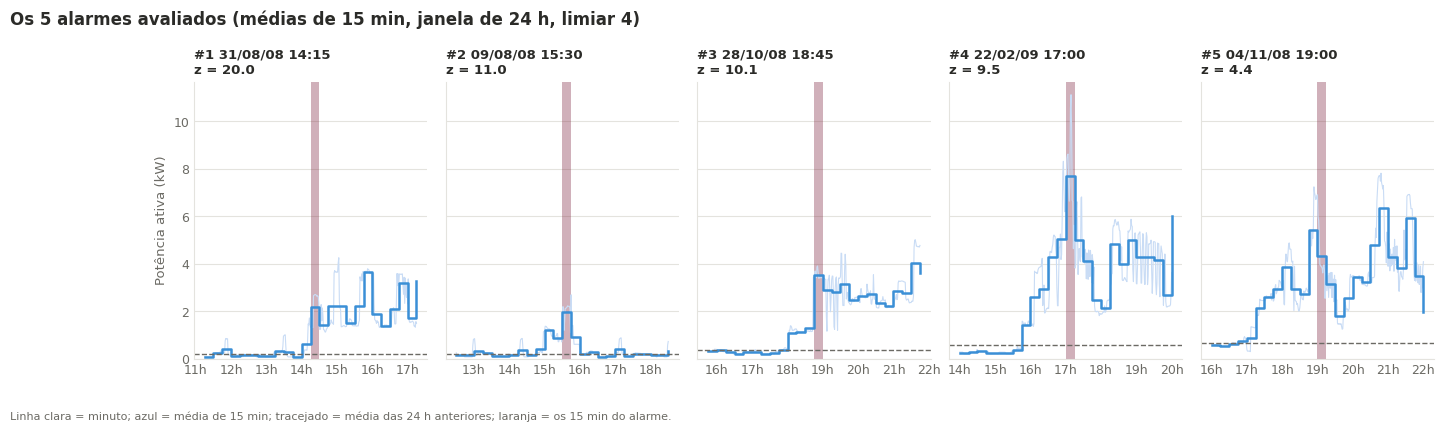

In [45]:
def plot_alarmes(caminho_png=None):
    """Os 5 alarmes avaliados: 3 h antes e 3 h depois de cada um."""
    fig, axes = plt.subplots(1, 5, figsize=(16, 3.6), sharey=True, gridspec_kw={"wspace": 0.08})
    for i, (ax, a) in enumerate(zip(axes, AVALIAR), start=1):
        t = pd.Timestamp(a)
        ini, fim = t - pd.Timedelta(hours=3), t + pd.Timedelta(hours=3)
        ax.plot(serie.loc[ini:fim].index, serie.loc[ini:fim].values, color="#c9dcf5", lw=0.8)
        ax.step(q15.loc[ini:fim].index, q15.loc[ini:fim].values, where="post", color=AZUL, lw=1.8)
        ax.axhline(alarmes.loc[t, "média 24 h"], color=TINTA_2, ls="--", lw=1)
        ax.axvspan(t, t + pd.Timedelta(minutes=15), color=LARANJA, alpha=0.35, lw=0)
        ax.set_title(f"#{i} {t:%d/%m/%y %H:%M}\nz = {alarmes.loc[t, 'z']:.1f}", loc="left", fontsize=9.5,
                     color=TINTA, fontweight="bold")
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Hh"))
        estilo(ax)
    axes[0].set_ylim(0, None)                     # eixo comum aos 5 painéis, desde zero
    axes[0].set_ylabel("Potência ativa (kW)", fontsize=9.5, color=TINTA_2)
    fig.suptitle("Os 5 alarmes avaliados (médias de 15 min, janela de 24 h, limiar 4)", x=0.01, ha="left",
                 y=1.08, fontsize=12, fontweight="bold", color=TINTA)
    fig.text(0.01, -0.06, "Linha clara = minuto; azul = média de 15 min; tracejado = média das 24 h anteriores; "
             "laranja = os 15 min do alarme.", fontsize=8, color=TINTA_2)
    if caminho_png:
        fig.savefig(caminho_png, dpi=150, bbox_inches="tight", facecolor="white")
    return fig


fig = plot_alarmes()
guardar_figura(fig, "parte_IV", "alarmes_avaliados")
plt.show()


**Avaliação dos 5 alarmes.**

| # | Quando | O que se vê | Real ou falso? |
|---|---|---|---|
| 1 | dom 31/08/2008 14:15 (z = 20) | Regresso das férias: depois de 25 dias a cerca de 0,2 kW, a casa volta a consumir 2,2 kW (aquecedor de água a reaquecer e «Outros»). | **Real**, mas benigno: é um acontecimento verdadeiro (o fim da ausência), sem ação necessária. |
| 2 | sáb 09/08/2008 15:30 (z = 11) | A meio da ausência, 1 a 2 kW durante cerca de uma hora, quase tudo em «Outros», sem cozinha nem lavandaria. | **Real**, e o mais útil: consumo numa casa que devia estar vazia (uma visita? um aparelho ligado?). É o tipo de anomalia que vale a pena avisar. |
| 3 | ter 28/10/2008 18:45 (z = 10) | Jantar normal (cozinha 569 Wh, 3,5 kW). O z é alto porque as 24 h anteriores incluem 27/10, um dia de consumo muito baixo (8,7 kWh). | **Falso**: consumo normal, comparado com uma janela anormalmente baixa. |
| 4 | dom 22/02/2009 17:00 (z = 9,5) | 7,7 kW de média durante 15 min, com todos os circuitos ligados ao mesmo tempo (lavandaria 1 003 Wh, cozinha, aquecedor e «Outros»). É a 3.ª média de 15 min mais alta de toda a janela. | **Real**: pico de consumo muito alto. Relevante para a potência contratada. |
| 5 | ter 04/11/2008 19:00 (z = 4,4) | Fim de tarde de inverno, máquina de roupa (650 Wh) e rotina normal; há valores parecidos antes e depois. Os dois dias anteriores foram baixos (14–15 kWh). | **Falso**: rotina normal, que só passa o limiar porque a janela vinha de dias calmos. |

**Resultado:** 3 alarmes reais (um deles benigno) e 2 falsos. Os dois falsos têm a mesma causa: a janela de 24 h inclui dias de consumo baixo, e o regresso ao normal parece anómalo.

### Recomendação à sala de controlo

- **Granularidade:** médias de 15 min, nunca leituras ao minuto. Ao minuto há dezenas de alarmes por dia, quase todos aparelhos a ligar.
- **Janela e limiar:** janela das últimas 24 h, com desvio mínimo de 0,1 kW, e **limiar 5 para alarme imediato** (cerca de 0,2 alarmes por dia, ou 7 por mês). Os alarmes entre 4 e 5 (cerca de 0,4 por dia a mais) podem ir para uma lista de revisão diária, sem interromper o operador. Nos 5 alarmes avaliados, o limiar 5 mantinha os 3 reais, eliminava o falso #5 e mantinha o falso #3.
- **Porquê 24 h e não 7 dias:** a janela de 7 dias dá menos alarmes, mas perde a anomalia mais útil, o consumo numa casa vazia (#2). Uma anomalia perdida numa casa vazia (possível intrusão ou avaria) custa mais do que alguns falsos alarmes por mês.
- **Ponto fraco conhecido:** depois de um dia de ausência, o regresso à rotina gera falsos alarmes (#3 e #5). Uma melhoria seria comparar cada leitura com o perfil típico daquela hora e dia da semana, em vez de só com as últimas 24 h.
- **Quedas e mudanças de nível** (ausências, mudanças de estação) não são para o z-score: ficam com o ADWIN sobre a energia diária, que as assinala com poucos dias de atraso. Antes de agir sobre uma deteção do ADWIN, confirmar se se repete na mesma altura do ano anterior (sazonal) ou não (possível mudança estrutural).